In [1]:
import torch
import matplotlib.pyplot as plt;
import numpy as np
from evo2 import Evo2

# Verify CUDA visibility inside WSL
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Load Evo2-1b
evo2_model = Evo2('evo2_1b_base', local_path='model/evo2_1b_base/evo2_1b_base.pt')

/home/tianp/EvoProject/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cuda
Loading model from model/evo2_1b_base/evo2_1b_base.pt...
Loading config from configs/evo2-1b-8k.yml...


[10/10/26 15:51:55] INFO     StripedHyena - INFO - Initializing StripedHyena with config:              ]8;id=539912;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=539913;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py#645\645]8;;\
                             {'model_name': 'shc-evo2-1b-8k-2T-v2', 'vocab_size': 512, 'hidden_size':              
                             1920, 'num_filters': 1920, 'attn_layer_idxs': [3, 10, 17, 24],                        
                             'hcl_layer_idxs': [2, 6, 9, 13, 16, 20, 23], 'hcm_layer_idxs': [1, 5, 8,              
                             12, 15, 19, 22], 'hcs_layer_idxs': [0, 4, 7, 11, 14, 18, 21],                         
                             'hcm_filter_length': 128, 'hcl_filter_groups': 1920, 'hcm_filter_groups':             
                             128, 'hcs_filter_groups': 128, 'hcs_filter_length': 7, 'num_layers': 25,              
                             'short_filter_length': 3, 'num_attention_heads': 15, 'short_filter_bias':             
                             False, 'mlp_init_method': 'torch.nn.init.zeros_',                                     
                             'mlp_output_init_method': 'torch.nn.init.zeros_', 'eps': 1e-06,                       
                             'state_size': 16, 'rotary_emb_base': 10000,                                           
                             'make_vocab_size_divisible_by': 8, 'inner_size_multiple_of': 16,                      
                             'inner_mlp_size': 5120, 'log_intermediate_values': False, 'proj_groups':              
                             1, 'hyena_filter_groups': 1, 'column_split_hyena': False, 'column_split':             
                             True, 'interleave': True, 'evo2_style_activations': True,                             
                             'model_parallel_size': 1, 'pipe_parallel_size': 1, 'tie_embeddings':                  
                             True, 'mha_out_proj_bias': True, 'hyena_out_proj_bias': True,                         
                             'hyena_flip_x1x2': False, 'qkv_proj_bias': False,                                     
                             'use_fp8_input_projections': False, 'max_seqlen': 8192, 'max_batch_size':             
                             1, 'final_norm': True, 'use_flash_attn': True, 'use_flash_rmsnorm':                   
                             False, 'use_flash_depthwise': False, 'use_flashfft': False,                           
                             'use_laughing_hyena': False, 'inference_mode': True, 'tokenizer_type':                
                             'CharLevelTokenizer', 'prefill_style': 'fft', 'mlp_activation': 'gelu',               
                             'print_activations': False}                                                           

                    INFO     StripedHyena - INFO - Initializing 25 blocks...                           ]8;id=539919;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=539920;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py#678\678]8;;\

                    INFO     StripedHyena - INFO - Distributing across 1 GPUs, approximately 25 layers ]8;id=539926;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=539927;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py#685\685]8;;\
                             per GPU                                                                               

  0%|          | 0/25 [00:00<?, ?it/s]

... (52 outputs left out)

100%|██████████| 25/25 [00:00<00:00, 68.19it/s]


                    INFO     StripedHyena - INFO - Initialized model                                   ]8;id=540235;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=540236;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/model.py#723\723]8;;\

                    INFO     vortex.model.utils - INFO - Loading model/evo2_1b_base/evo2_1b_base.pt     ]8;id=540243;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/utils.py\utils.py]8;;\:]8;id=540244;file:///home/tianp/EvoProject/.venv/lib/python3.12/site-packages/vortex/model/utils.py#92\92]8;;\

FileNotFoundError: [Errno 2] No such file or directory: 'model/evo2_1b_base/evo2_1b_base.pt'

In [3]:
with open("data/wildtype.txt", "r", encoding="utf-8") as file:
    sequence1 = file.read().replace("\n", "")
with open("data/benign_missense.txt", "r", encoding="utf-8") as file:
    sequence2 = file.read().replace("\n", "")

FileNotFoundError: [Errno 2] No such file or directory: 'data/wildtype.txt'

In [53]:
#load antisense sequences
sequence1 = "TACTCCCCTGCCCTCAACAAGATGTTTTGCCAACTGGCCAAGACCTGCCCTGTGCAGCTGTGGGTTGATTCCACACCCCCGCCCGGCACCCGCGTCCGCGCCATGGCCATCTACAAGCAGTCACAGCACATGACGGAGGTTGTGAGGCGCTGCCCCCACCATGAGCGCTGCTCAGATAGCGATG";
sequence2 = "TACTCCCCTGCCCTCAACAAGATGTTTTGCCAACTGGCCAAGACCTGCCCTGTGCAGCTGTGGGTTGATTCCACACCCCCGCCCGGCACCCGCGTCCGCGCCATGGCCATCTACAAGCAGTCACAGCACATGACGGATGTTGTGAGGCGCTGCCCCCACCATGAGCGCTGCTCAGATAGCGATG";

In [4]:
from Bio.Seq import Seq

#create sense sequence counterparts
antisense_seq = Seq(sequence1);
sequence1_opposite = antisense_seq.reverse_complement()
antisense_seq = Seq(sequence2);
sequence2_opposite = antisense_seq.reverse_complement()

print(sequence1_opposite)
print(sequence2_opposite)

# Get embeddings from Evo2-1b

# Layer to examine
layer_name = 'blocks.17.mlp'

input_ids1 = torch.tensor(
    evo2_model.tokenizer.tokenize(str(sequence1)),
    dtype=torch.int,
).unsqueeze(0).to(device)

input_ids2 = torch.tensor(
    evo2_model.tokenizer.tokenize(str(sequence2)),
    dtype=torch.int,
).unsqueeze(0).to(device)

input_ids1_opposite = torch.tensor(
    evo2_model.tokenizer.tokenize(str(sequence1_opposite)),
    dtype=torch.int,
).unsqueeze(0).to(device)

input_ids2_opposite = torch.tensor(
    evo2_model.tokenizer.tokenize(str(sequence2_opposite)),
    dtype=torch.int,
).unsqueeze(0).to(device)

outputs, embeddings1 = evo2_model(
    input_ids1, 
    return_embeddings=True, 
    layer_names=[layer_name]
)

outputs, embeddings2 = evo2_model(
    input_ids2, 
    return_embeddings=True, 
    layer_names=[layer_name]
)

outputs, embeddings1_opposite = evo2_model(
    input_ids1_opposite, 
    return_embeddings=True, 
    layer_names=[layer_name]
)

outputs, embeddings2_opposite = evo2_model(
    input_ids2_opposite, 
    return_embeddings=True, 
    layer_names=[layer_name]
)

embedding_matrix1 = embeddings1[layer_name]
embedding_matrix2 = embeddings2[layer_name]
embedding_matrix1_opposite = embeddings1_opposite[layer_name]
embedding_matrix2_opposite = embeddings2_opposite[layer_name]


print("Embedding matrix shape 1:", embedding_matrix1.shape)
print("Embedding matrix shape 2:", embedding_matrix2.shape)
print("Embedding matrix opposite shape 1:", embedding_matrix1_opposite.shape)
print("Embedding matrix opposite shape 2:", embedding_matrix2_opposite.shape)

matrix1 = embedding_matrix1.squeeze(0).detach().cpu().to(torch.float32).numpy()
matrix2 = embedding_matrix2.squeeze(0).detach().cpu().to(torch.float32).numpy()
matrix1_opp = embedding_matrix1_opposite.squeeze(0).detach().cpu().to(torch.float32).numpy()
matrix2_opp = embedding_matrix2_opposite.squeeze(0).detach().cpu().to(torch.float32).numpy()

difference_matrix = matrix1-matrix2;
difference_matrix_opp = matrix1_opp-matrix2_opp;

# get variables
total_size = difference_matrix.shape[0] - 1
print(total_size)
cut_site = next((i for i, (a, b) in enumerate(zip(sequence1, sequence2)) if a != b), min(len(sequence1), len(sequence2)))
print(cut_site)

# flip sense matrix diff
difference_matrix_opp = np.flip(difference_matrix_opp, axis=0)

#cut down to size
difference_matrix_opp = difference_matrix_opp[0:cut_site, :]
difference_matrix = difference_matrix[cut_site:total_size, :]

#combine
combined_diff_matrix = np.vstack((difference_matrix_opp, difference_matrix))

#print
print("Combined Difference Matrix:", combined_diff_matrix.shape)

NameError: name 'sequence1' is not defined

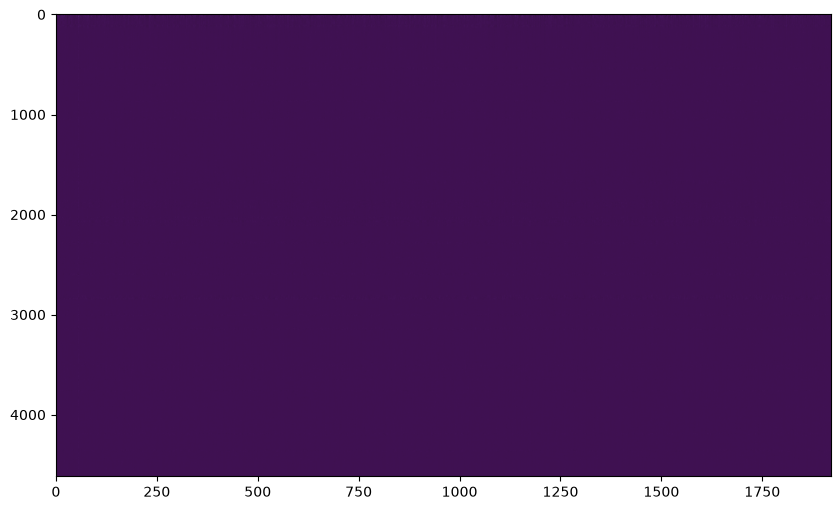

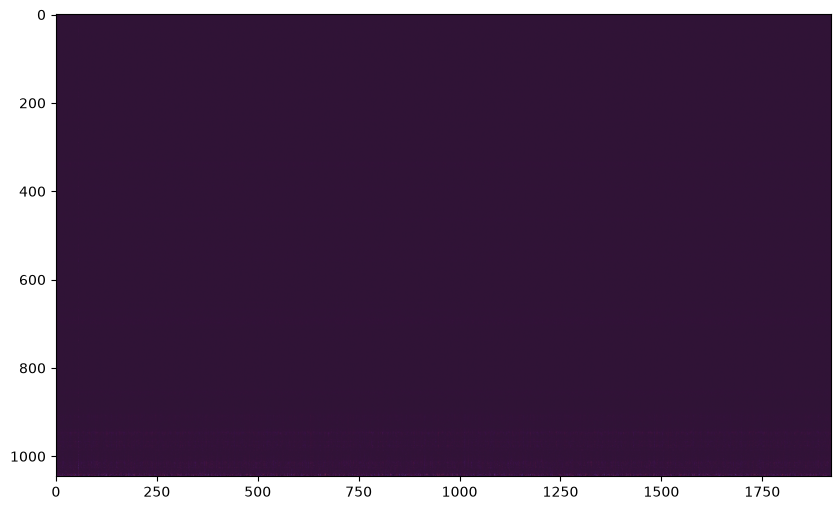

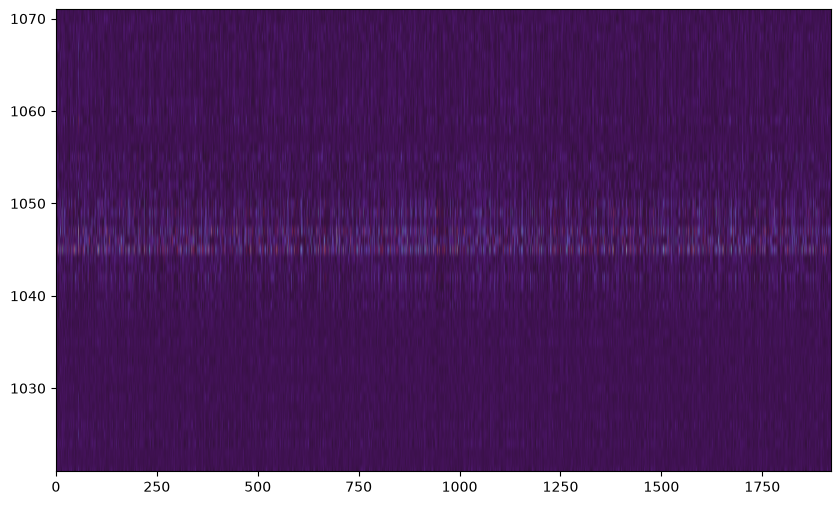

In [11]:
plt.figure(figsize=(10, 6))
plt.imshow(difference_matrix, aspect='auto', cmap='twilight')
plt.show()

plt.figure(figsize=(10, 6))
plt.imshow(difference_matrix_opp, aspect='auto', cmap='twilight')
plt.show()

plt.figure(figsize=(10, 6))
plt.imshow(combined_diff_matrix, aspect='auto', cmap='twilight')
plt.ylim(cut_site-25, cut_site+25)
plt.show()